# 01 — Exploratory data analysis

A first look at the Home Credit application data: target balance, missingness and the strongest raw signals. This uses the public Kaggle dataset in `data/raw/`.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
# run from repo root so `src` and configs resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
pd.set_option("display.max_columns", 60)

In [2]:
from src.data.load_data import load_config, load_application
cfg = load_config()
app = load_application(cfg, 'train')
print(app.shape)
app.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,...,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,...,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,...,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,...,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,1,0,0,Core staff,1.0,...,0.0,0.0,0.0,-1106.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Target balance

The positive class (default) is rare, which drives most of the modelling choices later.

default rate: 0.0807  (24,825 of 307,511)


<Axes: title={'center': 'TARGET (0 = repaid, 1 = default)'}, xlabel='TARGET'>

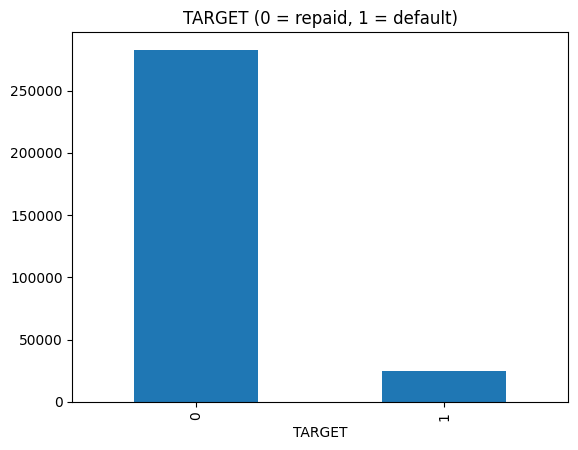

In [3]:
rate = app['TARGET'].mean()
print(f'default rate: {rate:.4f}  ({app.TARGET.sum():,} of {len(app):,})')
app['TARGET'].value_counts().plot.bar(title='TARGET (0 = repaid, 1 = default)')

## Missing values

Several columns are mostly empty; the tree models handle NaNs natively, and the linear baseline imputes them.

In [4]:
miss = app.isna().mean().sort_values(ascending=False)
miss.head(15)

COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_AVG               0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_AVG             0.664978
YEARS_BUILD_MODE            0.664978
dtype: float64

## External scores vs default

The three `EXT_SOURCE_*` columns are the single strongest raw signals in this dataset.

In [5]:
for c in ['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']:
    print(c, 'corr with TARGET:', round(app[c].corr(app['TARGET']), 4))

EXT_SOURCE_1 corr with TARGET: -0.1553
EXT_SOURCE_2 corr with TARGET: -0.1605
EXT_SOURCE_3 corr with TARGET: -0.1789


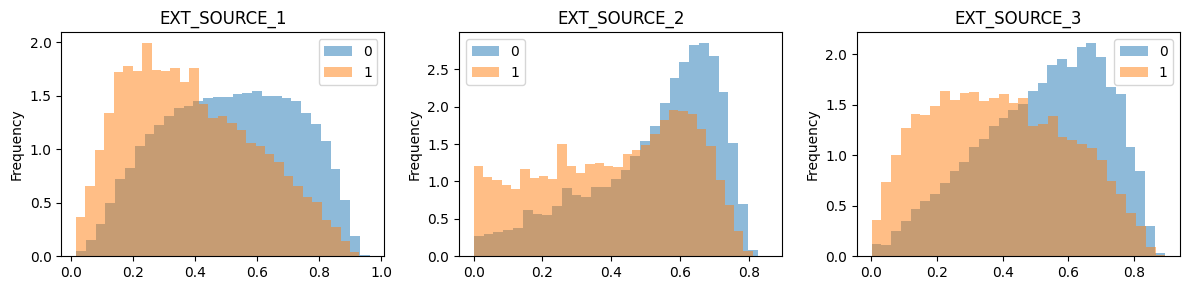

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,3, figsize=(12,3))
for i,c in enumerate(['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    app.groupby('TARGET')[c].plot.hist(bins=30, alpha=0.5, ax=ax[i], legend=True, title=c, density=True)
plt.tight_layout()

## A couple of known data issues

`DAYS_EMPLOYED` has a sentinel value (365243) for people who are not employed, and `CODE_GENDER` has a few `XNA` values. Both are handled in `clean_application`.

In [7]:
print('DAYS_EMPLOYED == 365243:', int((app['DAYS_EMPLOYED']==365243).sum()))
print('CODE_GENDER value counts:')
print(app['CODE_GENDER'].value_counts())

DAYS_EMPLOYED == 365243: 55374
CODE_GENDER value counts:
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64
